# First forecasting baseline: previous-week consumption

## Experiment
Predict hourly end-user energy in MWh by copying the observation **168 elapsed hours earlier**. There is no fitted model.

- Development evaluation: October 1 through December 31, 2024, using Swiss local dates.
- Forecast issue time: noon Europe/Zurich on the preceding calendar day, predicting all hours of the following local day. The autumn clock-change day has 25 target hours.
- Historical observations may be reused as they become available for subsequent daily forecasts; no target from the delivery day enters that day's forecast.
- A separate later period is still needed for final evaluation: 2024 has already been explored.

## Provisional assumptions
The source timestamps are assumed to label interval ends. We also assume that the previous-week observations used here were published by each forecast issue time. The annual workbook contains historical values and cannot establish their publication times or revision history. This is a retrospective development experiment.

A fixed 168-hour UTC lag is deliberately simple. Around daylight saving transitions it can refer to a different Swiss clock hour than the target. A baseline matching local weekday and clock hour would require an explicit policy for missing and repeated hours.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src" / "preparation.py").exists():
    project_dir = project_dir.parent
assert (project_dir / "src" / "preparation.py").exists(), "Run from the project or notebooks folder."
src_dir = str(project_dir / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from preparation import (
    load_quarter_hour_data,
    prepare_quarter_hour_data,
    aggregate_hourly_energy,
)

## 1. Reuse the preparation pipeline
This notebook runs independently of notebook 01. Loading and preparation happen here through the reusable functions.

In [2]:
file_path = project_dir / "data" / "raw" / "EnergieUebersichtCH-2024.xlsx"
raw = load_quarter_hour_data(file_path)
prepared = prepare_quarter_hour_data(raw)
hourly = aggregate_hourly_energy(prepared)

assert hourly.index.is_unique
assert hourly.index.is_monotonic_increasing
assert hourly.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert hourly["interval_count"].eq(4).all()
assert hourly["end_user_energy_mwh"].notna().all()
assert np.isclose(raw["end_user_energy_kwh"].sum(), hourly["end_user_energy_kwh"].sum(), rtol=1e-12, atol=0.01)
print(f"Prepared {len(hourly):,} complete hourly observations.")

Prepared 8,784 complete hourly observations.


## 2. Make the predictions before selecting the evaluation period
`shift(168)` moves observations forward by 168 rows. Because we checked that the UTC index is continuous and hourly, this is exactly 168 elapsed hours.

The baseline is a rolling daily experiment: a December forecast can use earlier December observations, subject to the stated availability assumption.

In [3]:
predictions = hourly[["end_user_energy_mwh", "hour_start_local"]].rename(
    columns={"end_user_energy_mwh": "actual_mwh"}
).copy()
predictions["prediction_mwh"] = predictions["actual_mwh"].shift(168)
predictions["source_start_utc"] = predictions.index - pd.Timedelta(hours=168)

# Work with local calendar dates to define noon on the preceding day.
local_dates = predictions["hour_start_local"].dt.tz_localize(None).dt.normalize()
issue_times_naive = local_dates - pd.Timedelta(days=1) + pd.Timedelta(hours=12)
predictions["issue_time_utc"] = (
    issue_times_naive.dt.tz_localize("Europe/Zurich").dt.tz_convert("UTC")
)

start_local = pd.Timestamp("2024-10-01", tz="Europe/Zurich")
end_local = pd.Timestamp("2025-01-01", tz="Europe/Zurich")
mask = (
    (predictions["hour_start_local"] >= start_local)
    & (predictions["hour_start_local"] < end_local)
)
evaluation = predictions.loc[mask].copy()
expected_hours = int((end_local.tz_convert("UTC") - start_local.tz_convert("UTC")) / pd.Timedelta(hours=1))
assert len(evaluation) == expected_hours
assert evaluation[["actual_mwh", "prediction_mwh"]].notna().all().all()
# The complete source interval must finish before the forecast is issued.
assert (evaluation["source_start_utc"] + pd.Timedelta(hours=1) <= evaluation["issue_time_utc"]).all()

print(f"Evaluation: {len(evaluation):,} hours across {evaluation['hour_start_local'].dt.date.nunique()} local days.")
display(evaluation.head())

Evaluation: 2,209 hours across 92 local days.


,actual_mwh,hour_start_local,prediction_mwh,source_start_utc,issue_time_utc
interval_start_utc,,,,,
2024-09-30 22:00:00+00:00,5016.204679,2024-10-01 00:00:00+02:00,5083.890993,2024-09-23 22:00:00+00:00,2024-09-30 10:00:00+00:00
2024-09-30 23:00:00+00:00,4832.122369,2024-10-01 01:00:00+02:00,4914.790869,2024-09-23 23:00:00+00:00,2024-09-30 10:00:00+00:00
2024-10-01 00:00:00+00:00,4712.753045,2024-10-01 02:00:00+02:00,4776.334720,2024-09-24 00:00:00+00:00,2024-09-30 10:00:00+00:00
2024-10-01 01:00:00+00:00,4569.840501,2024-10-01 03:00:00+02:00,4631.923025,2024-09-24 01:00:00+00:00,2024-09-30 10:00:00+00:00
2024-10-01 02:00:00+00:00,4541.955075,2024-10-01 04:00:00+02:00,4576.235199,2024-09-24 02:00:00+00:00,2024-09-30 10:00:00+00:00


## 3. Measure the errors
Error is prediction minus actual energy. Positive error means overprediction.

- **MAE**: mean absolute error in MWh; the typical magnitude of error across evaluated hours.
- **RMSE**: square root of mean squared error in MWh; larger errors receive more weight.
- **Mean error**: signed average error, useful for spotting overall overprediction or underprediction. Errors can cancel here.

These metrics weight every evaluated hour equally.

In [4]:
evaluation["error_mwh"] = evaluation["prediction_mwh"] - evaluation["actual_mwh"]
evaluation["absolute_error_mwh"] = evaluation["error_mwh"].abs()

scores = pd.Series({
    "MAE (MWh)": evaluation["absolute_error_mwh"].mean(),
    "RMSE (MWh)": np.sqrt(evaluation["error_mwh"].pow(2).mean()),
    "Mean error (MWh)": evaluation["error_mwh"].mean(),
}, name="Previous-week baseline")
display(scores.round(2))

monthly_errors = (
    evaluation.assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .agg(hours=("actual_mwh", "size"), mae_mwh=("absolute_error_mwh", "mean"))
)
display(monthly_errors.round(2))

MAE (MWh)           332.26
RMSE (MWh)          445.51
Mean error (MWh)    -69.27
Name: Previous-week baseline, dtype: float64

,hours,mae_mwh
local_month,,
10,745,181.89
11,720,406.01
12,744,411.47


## 4. Inspect one week
The plot shows October 7?13 in Swiss local time. An aggregate score alone cannot show when the baseline misses peaks or changes in consumption.

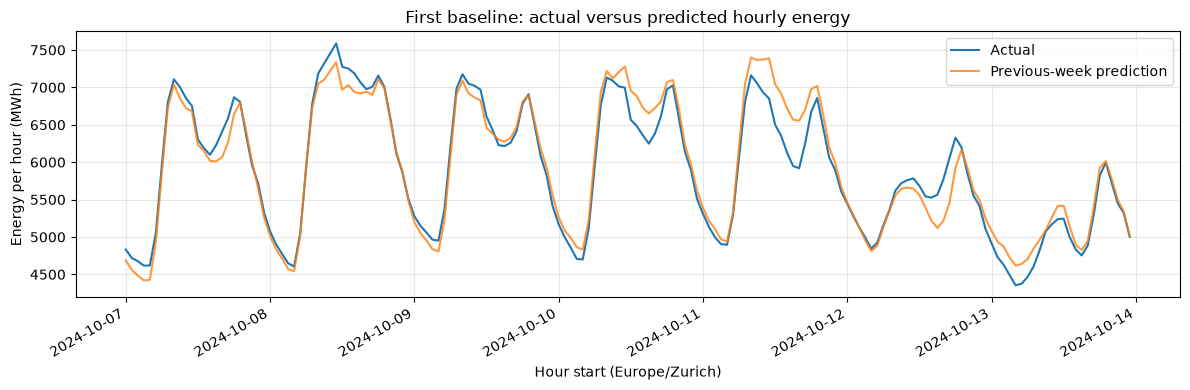

In [5]:
week = evaluation.loc[
    (evaluation["hour_start_local"] >= pd.Timestamp("2024-10-07", tz="Europe/Zurich"))
    & (evaluation["hour_start_local"] < pd.Timestamp("2024-10-14", tz="Europe/Zurich"))
]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week["hour_start_local"], week["actual_mwh"], label="Actual")
ax.plot(week["hour_start_local"], week["prediction_mwh"], label="Previous-week prediction", alpha=0.8)
ax.set_title("First baseline: actual versus predicted hourly energy")
ax.set_xlabel("Hour start (Europe/Zurich)")
ax.set_ylabel("Energy per hour (MWh)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Learning checkpoint
1. Read the MAE aloud as an error in hourly energy, in MWh.
2. Compare the three monthly MAEs. Which month was hardest for this baseline?
3. Find a period in the plot where prediction and actual consumption separate. The plot alone does not establish why.

Next experiments: inspect the largest errors and compare another simple baseline on exactly the same evaluation hours. Resolve timestamp conventions and historical data availability before treating the scores as operational forecast performance.